The code in this notebook adjusted from 
`https://github.com/CGAL/cgal-swig-bindings/blob/main/examples/python/vd_2_point_location.py`

# 1. A Configuration of Points

In [1]:
from matplotlib import pyplot as plt

In [2]:
points = []
points.append((0, 0))
points.append((100, 0))
points.append((100, 100))
points.append((0, 100))
points.append((200, 100))
points.append((100, 200))

In [3]:
print('the points :')
for point in points:
    print(point)

the points :
(0, 0)
(100, 0)
(100, 100)
(0, 100)
(200, 100)
(100, 200)


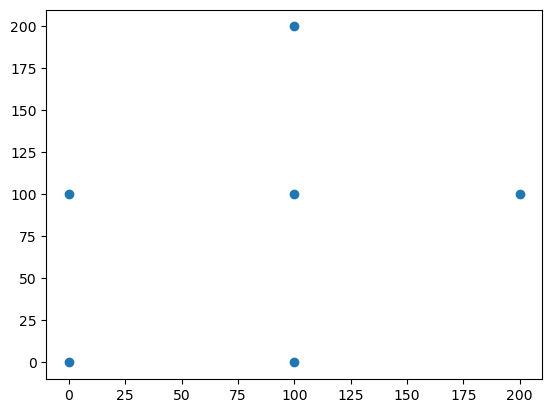

In [4]:
x = [x for (x, y) in points]
y = [y for (x, y) in points]
plt.scatter(x, y)
plt.show()

# 2. Computing a Voronoi Diagram

In [5]:
from __future__ import print_function
from CGAL.CGAL_Kernel import Point_2
from CGAL.CGAL_Voronoi_diagram_2 import Voronoi_diagram_2
from CGAL.CGAL_Voronoi_diagram_2 import Voronoi_diagram_2_Halfedge_handle

In [6]:
sites = [Point_2(x, y) for (x, y) in points]

In [7]:
print('the sites :')
for site in sites:
    print(site)

the sites :
0 0
100 0
100 100
0 100
200 100
100 200


In [8]:
vd = Voronoi_diagram_2(sites)

# 3 Querying the Voronoi Diagram

To print the information computed by the Voronoi diagram, we formulate queries.

In [9]:
def print_query_type(vd, query_point):
    """
    Prints the type of the query point.
    """
    lr = vd.locate(query_point)
    if lr.is_vertex_handle():
        print(" is on a vertex.")
    elif lr.is_halfedge_handle():
        print(" is on an edge.")
    elif lr.is_face_handle():
        print(" is in a face.")
    else:
        print(" could not be located?")

In [10]:
query_point0 = sites[0]
print('The query point', query_point0, end='')
print_query_type(vd, query_point0)

The query point 0 0 is in a face.


The faces of a Voronoi diagram are stored in a half edge data structure.

In [11]:
def print_endpoint(e, is_src):
    """
    Prints the end point of an edge e
    of the Voronoi diagram.
    If is_src, then also the start point of e
    is printed.
    """
    print("\t", end='')
    if is_src:
        if e.has_source():
            print(e.source().point())
        else:
            print("point at infinity")
    else:
        if e.has_target():
            print(e.target().point())
        else:
            print("point at infinity")

In [12]:
def print_vertices(vd, query_point):
    """
    Prints the vertices of a query point
    that is in a face of the Voronoi diagram vd.
    """
    lr = vd.locate(query_point)
    if not lr.is_face_handle():
        print("The query point is not in a face.")
    else:
        f = lr.get_face_handle()
        print("The vertices of the Voronoi face are (in counterclockwise order):")
        ec_start = f.outer_ccb()
        if ec_start.hasNext():
            done = ec_start.next()
            iter = Voronoi_diagram_2_Halfedge_handle()
            while True:
                iter = ec_start.next()
                print_endpoint(iter, False)
                if iter == done:
                    break

In [13]:
print('The query point', query_point0, end='')
print_query_type(vd, query_point0)
print_vertices(vd, query_point0)

The query point 0 0 is in a face.
The vertices of the Voronoi face are (in counterclockwise order):
	50 50
	point at infinity


In [14]:
query_point2 = sites[2]
print('The query point', query_point2, end='')
print_query_type(vd, query_point2)
print_vertices(vd, query_point2)

The query point 100 100 is in a face.
The vertices of the Voronoi face are (in counterclockwise order):
	150 50
	150 150
	50 150
	50 50


It is a good exercise to plot all vertices and edges using matplotlib.